<a href="https://colab.research.google.com/github/Reapfan/CryptoAnalytics/blob/main/DA_CA_Hierarch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [264]:
# Импорт библиотек
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline
import os
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

In [265]:
# Импорт файла целиком
from google.colab import files
uploaded = files.upload()

In [266]:
# Чтение файла
df = pd.read_csv("/content/Lolypops.dat", sep=";")
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [267]:
# Кластеризуем данные, расстояние между кластерами - ward, расстояние между элементами - эвклидово
link = linkage(df, 'ward', 'euclidean')

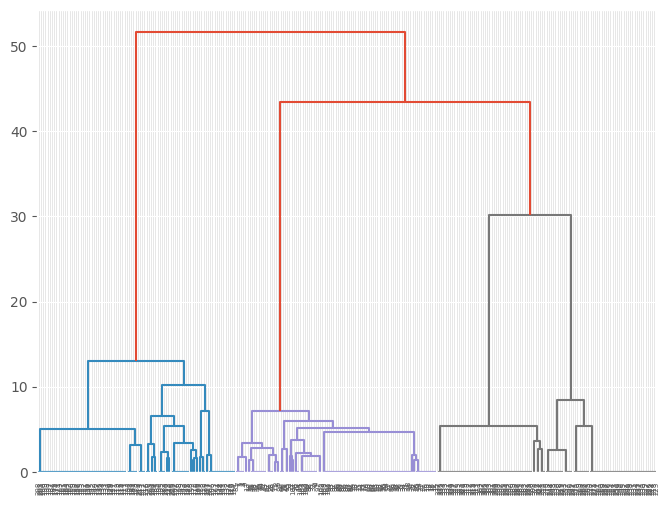

In [268]:
# Строим базовую дендрограмму
fig = plt.figure(figsize=(8, 6))
dn = dendrogram(link, labels= df.index.tolist())

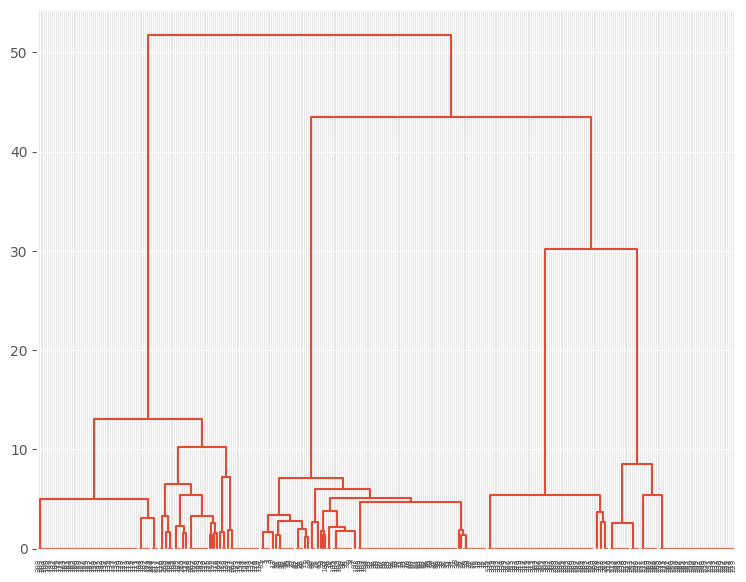

In [269]:
# Строим дендрограмму без деления на кластеры
fig = plt.figure(figsize=(9, 7))
dn = dendrogram(link, color_threshold = -1, labels= df.index.tolist())

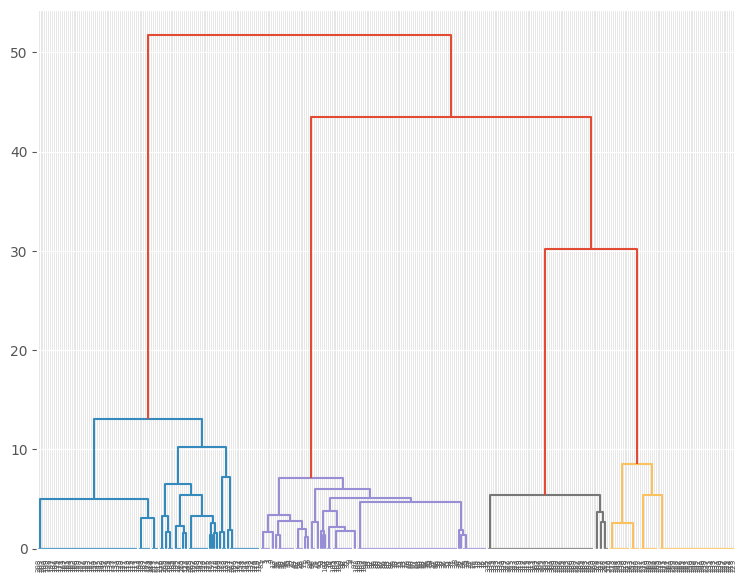

In [270]:
# Строим дендрограмму со своим порогом расстояния
fig = plt.figure(figsize=(9, 7))
dn = dendrogram(link, color_threshold = 14, labels= df.index.tolist())

In [271]:
# Добавим информацию о кластерах в данные
df['cluster'] = fcluster(link, 14, criterion='distance')
print(df)

     V1  V2  V3  V4  V5  V6  V7  V8  V9  V10  V11  cluster
0     4   5   5   5   3   3   3   3   3    3    3        2
1     5   4   5   5   3   3   3   3   3    3    3        2
2     5   5   4   5   3   3   3   3   3    3    3        2
3     5   4   5   5   3   3   3   3   3    3    3        2
4     4   5   5   5   3   3   3   3   3    3    3        2
..   ..  ..  ..  ..  ..  ..  ..  ..  ..  ...  ...      ...
333   3   3   3   3   3   3   5   5   3    3    3        3
334   3   3   3   3   3   3   5   5   3    3    3        3
335   3   3   3   3   3   3   5   5   3    3    3        3
336   3   3   3   3   3   3   5   5   3    3    3        3
337   3   3   3   3   3   3   5   5   3    3    3        3

[338 rows x 12 columns]


In [272]:
# Сгруппируем по кластерам и посчитаем средние значения по критериям
df.groupby('cluster').mean()
# Получаем понимание 4 кластеров: болеющие, чистюли, мыслители, сладкоежки.

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
1,2.824074,2.833333,2.768519,2.620370,2.611111,2.583333,2.750000,2.916667,4.953704,4.814815,4.861111
2,4.845455,4.800000,4.836364,4.681818,3.036364,3.036364,3.000000,2.990909,3.072727,3.045455,3.045455
3,3.000000,2.966102,2.966102,2.915254,2.915254,2.949153,4.915254,4.915254,3.000000,3.000000,3.000000
4,3.000000,3.000000,3.000000,3.000000,4.852459,4.852459,3.000000,2.918033,2.754098,2.754098,2.754098


In [273]:
# Сравниваем размеры кластеров
df.groupby('cluster').size()

,0
cluster,
1,108
2,110
3,59
4,61


In [274]:
# Выделяем второй столбец link с расстояниями
dist = link[:, 2]

Text(0, 0.5, 'Расстояние')

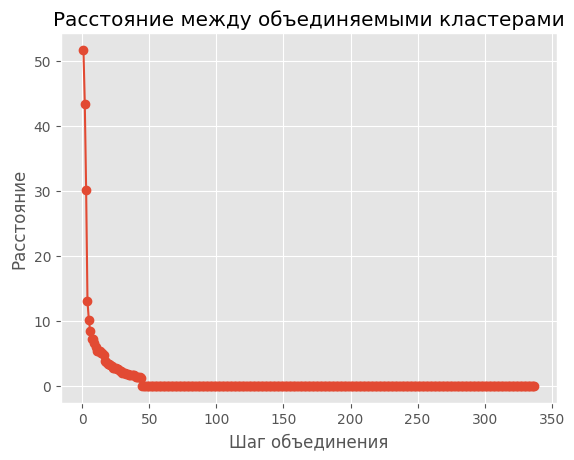

In [275]:
# Строим график для каменистой осыпи
dist_rev = dist[::-1]
idxs = range(1, len(dist)+1)
plt.plot(idxs, dist_rev, marker='o')
plt.title('Расстояние между объединяемыми кластерами')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние')

Text(0, 0.5, 'Расстояние')

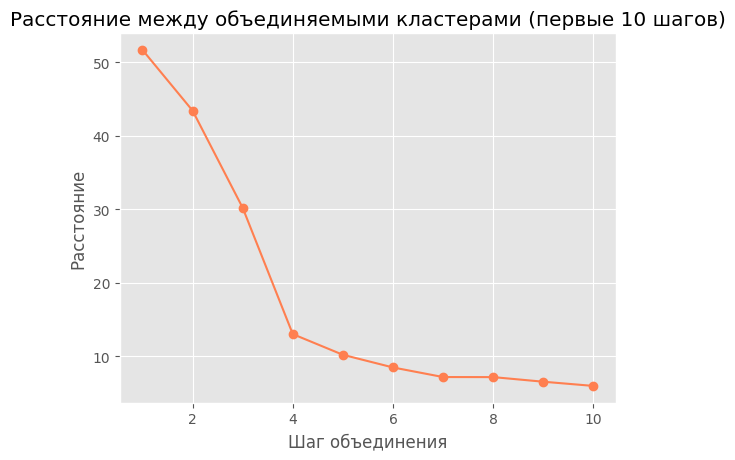

In [276]:
# Рассмотрим только начало каменистой осыпи, видим, что после 4 кластеров расстояние между кластерами перестаёт резко меняться
n = 10
plt.plot(idxs[:n], dist_rev[:n], marker='o', color='coral')
plt.title(f'Расстояние между объединяемыми кластерами (первые {n} шагов)')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние')

In [277]:
# Догрузим библиотеку
from sklearn import preprocessing

In [278]:
# Стандартизуем данные для сравнения, приведём к нулевому среднему и единичной стд
stand = preprocessing.StandardScaler()
# Вычисляем параметры стандартизации
df = pd.read_csv("/content/Lolypops.dat", sep=";")
stand.fit(df)
# Преобразуем данные в стандартизированные
x = stand.transform(df)
x = pd.DataFrame(x, index = df.index, columns=df.columns)

In [279]:
# Посмотрим часть данных
x.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,0.477424,1.542809,1.499214,1.603442,-0.239138,-0.235068,-0.301875,-0.353342,-0.623343,-0.594459,-0.600745
1,1.525275,0.495682,1.499214,1.603442,-0.239138,-0.235068,-0.301875,-0.353342,-0.623343,-0.594459,-0.600745
2,1.525275,1.542809,0.487768,1.603442,-0.239138,-0.235068,-0.301875,-0.353342,-0.623343,-0.594459,-0.600745
3,1.525275,0.495682,1.499214,1.603442,-0.239138,-0.235068,-0.301875,-0.353342,-0.623343,-0.594459,-0.600745
4,0.477424,1.542809,1.499214,1.603442,-0.239138,-0.235068,-0.301875,-0.353342,-0.623343,-0.594459,-0.600745


In [280]:
# Аналогично строим кластеризацию
link = linkage(x, 'ward', 'euclidean')

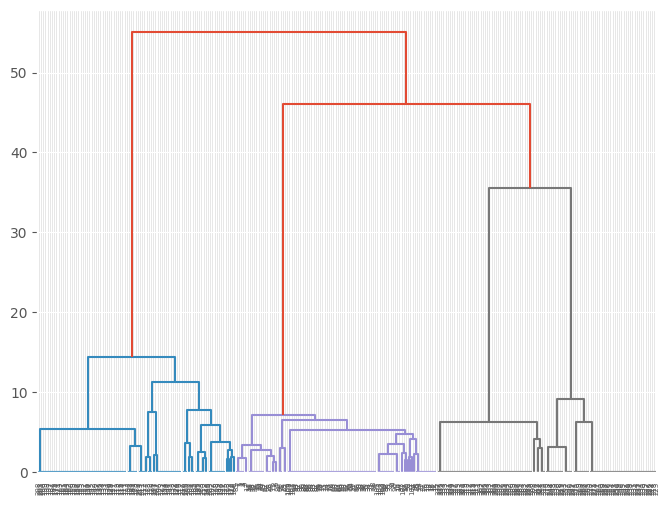

In [281]:
# Аналогично строим дендрограмму
fig = plt.figure(figsize=(8, 6))
dn = dendrogram(link, labels= df.index.tolist())

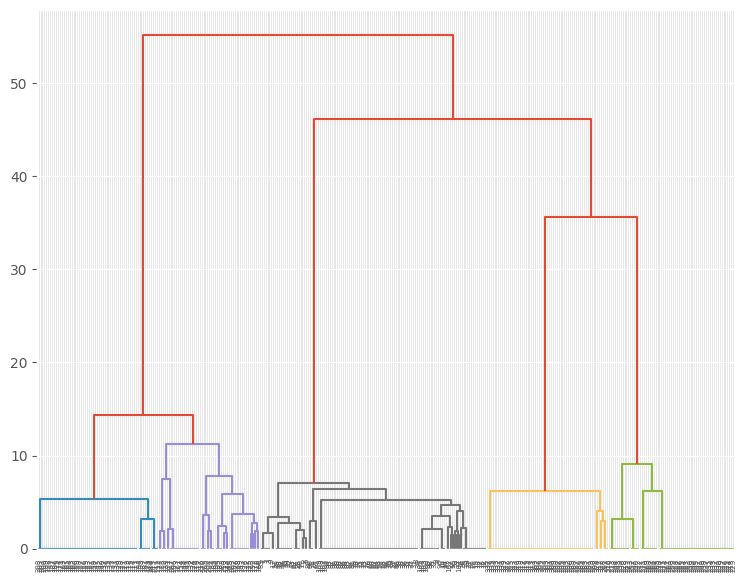

In [282]:
# Аналогично строим дендрограмму со своим порогом расстояния
fig = plt.figure(figsize=(9, 7))
dn = dendrogram(link, color_threshold = 14, labels= df.index.tolist())
# Получили больше кластеров

In [283]:
# Добавим информацию о кластерах в данные
x['cluster'] = fcluster(link, 14, criterion='distance')

In [284]:
# Сгруппируем по кластерам и посчитаем средние значения по критериям
x.groupby('cluster').mean()
# Получаем понимание 5 кластеров. Они аналогичны предыдущим, но первый развалился на 2 разных

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
1,-0.570428,-0.551446,-0.523678,-0.415044,-0.239138,-0.235068,-0.301875,-0.353342,1.372225,1.382953,1.417340
2,-0.976738,-0.936105,-1.039721,-1.259512,-1.228875,-1.292562,-0.955628,-0.577179,1.421168,1.345587,1.330189
3,1.363335,1.333383,1.333705,1.282320,-0.197149,-0.193196,-0.301875,-0.364421,-0.548231,-0.545356,-0.552422
4,-0.570428,-0.586942,-0.557964,-0.500573,-0.336993,-0.293619,1.970459,1.980719,-0.623343,-0.594459,-0.600745
5,-0.570428,-0.551446,-0.523678,-0.415044,1.899885,1.898026,-0.301875,-0.453233,-0.877309,-0.860094,-0.862162


In [285]:
# Сравниваем размеры кластеров
x.groupby('cluster').size()

,0
cluster,
1,59
2,49
3,110
4,59
5,61


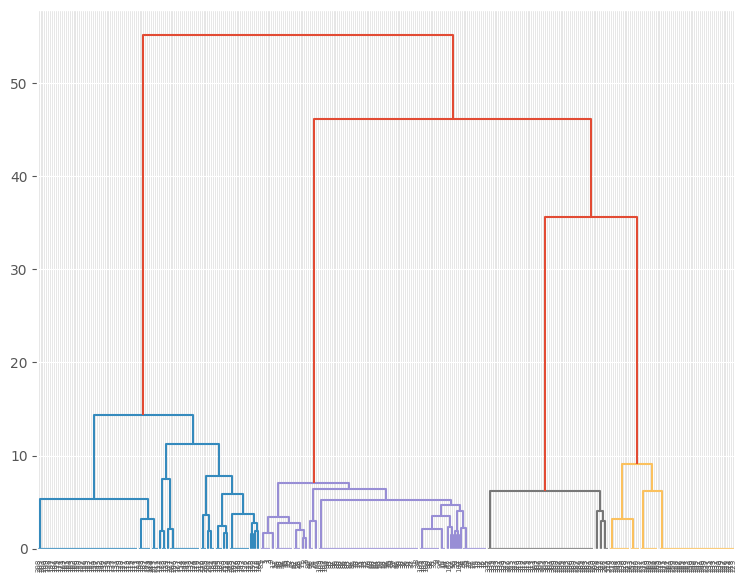

In [286]:
# Строим дендрограмму с большим порогом расстояния
fig = plt.figure(figsize=(9, 7))
dn = dendrogram(link, color_threshold = 16, labels= df.index.tolist())

In [287]:
# Добавим информацию о кластерах в данные
x['cluster'] = fcluster(link, 16, criterion='distance')

In [288]:
# Сгруппируем по кластерам и посчитаем средние значения по критериям
x.groupby('cluster').mean()
# Получаем старые добрые 4 кластера

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
1,-0.754772,-0.725967,-0.757809,-0.798182,-0.688185,-0.714857,-0.598485,-0.454898,1.394431,1.366000,1.377799
2,1.363335,1.333383,1.333705,1.282320,-0.197149,-0.193196,-0.301875,-0.364421,-0.548231,-0.545356,-0.552422
3,-0.570428,-0.586942,-0.557964,-0.500573,-0.336993,-0.293619,1.970459,1.980719,-0.623343,-0.594459,-0.600745
4,-0.570428,-0.551446,-0.523678,-0.415044,1.899885,1.898026,-0.301875,-0.453233,-0.877309,-0.860094,-0.862162


In [289]:
# Сравниваем размеры кластеров
x.groupby('cluster').size()

,0
cluster,
1,108
2,110
3,59
4,61


Text(0, 0.5, 'Расстояние')

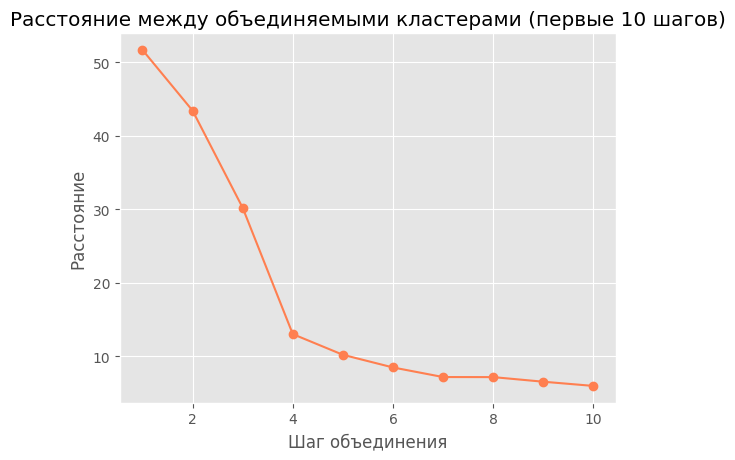

In [290]:
# Каменистой осыпью подтверждаем, что кластеров всё же 4
dist = link[:, 2]
n = 10
plt.plot(idxs[:n], dist_rev[:n], marker='o', color='coral')
plt.title(f'Расстояние между объединяемыми кластерами (первые {n} шагов)')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние')

In [291]:
# Догрузим библиотеки
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier

In [292]:
# Загрузим изначальные стандартизированные данные
stand = preprocessing.StandardScaler()
df = pd.read_csv("/content/Lolypops.dat", sep=";")
stand.fit(df)
x = stand.transform(df)
x = pd.DataFrame(x, index = df.index, columns=df.columns)

# Разобьём данные на 4 кластера и вынесем метки кластеров
k = 4
hc = AgglomerativeClustering(n_clusters=k, linkage='ward')
labels = hc.fit_predict(x)

In [293]:
# Понижаем размерность до 2-х признаков
pca = PCA(n_components=2, random_state=1000)
X_pca = pca.fit_transform(x)

In [294]:
# Обучаем KNN на наших 2d-признаках и метках кластеров
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_pca, labels)

KNeighborsClassifier()

In [295]:
# Построение сетки
x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
step = 0.05
xx, yy = np.meshgrid(np.arange(x_min, x_max, step),
                     np.arange(y_min, y_max, step))

In [296]:
# Предсказываем результат для каждой точки сетки
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

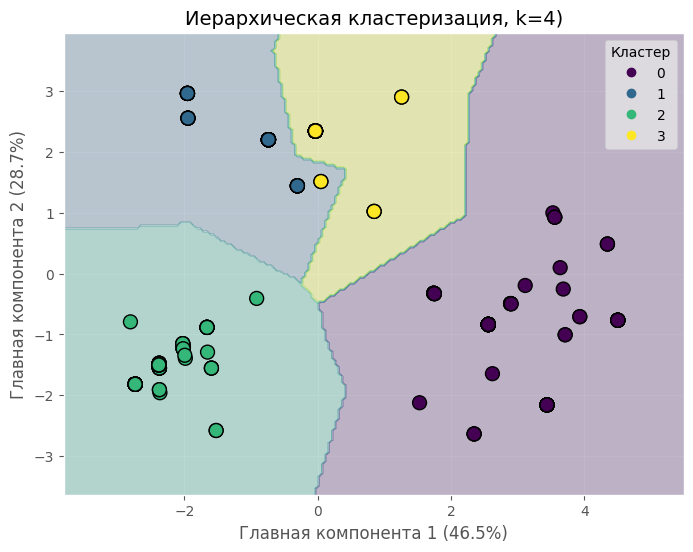

In [297]:
# Строим области кластеров
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.25, cmap='viridis')
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels,
                      cmap='viridis', edgecolor='black', s=100, linewidth=1)

plt.title(f'Иерархическая кластеризация, k={k})', fontsize=14)
plt.xlabel(f'Главная компонента 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
plt.ylabel(f'Главная компонента 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
plt.legend(*scatter.legend_elements(), title="Кластер")
plt.grid(True, alpha=0.3)
plt.show()

In [298]:
# Догрузим библиотеки
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [299]:
# Добавляем метки кластеров в исходный датафрейм
x['cluster'] = labels
# Считаем средние значения признаков для каждого кластера
cluster_means = x.groupby('cluster')[x.columns.drop('cluster')].mean()

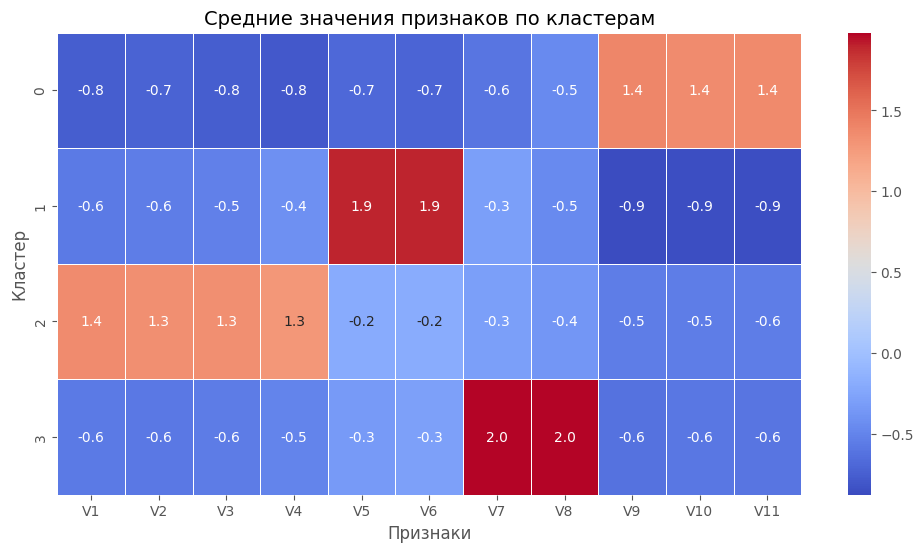

In [300]:
# Строим хитмап
plt.figure(figsize=(12, 6))
sns.heatmap(cluster_means,
            annot=True,
            cmap='coolwarm',
            fmt=".1f",
            linewidths=.5)
plt.title('Средние значения признаков по кластерам', fontsize=14)
plt.xlabel('Признаки')
plt.ylabel('Кластер')
plt.show()